# Polynomial Regression with Python and sklearn

Data source: https://www.kaggle.com/datasets/rutultrivedi/polynomial-regression-sample-dataset

In [1]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn import preprocessing as prep
import matplotlib.pyplot as plt
import seaborn as sns


## Step 1: Load the Dataset

In [2]:

# Load the dataset
data = pd.read_csv('kaggle_data.csv')

# Display the first few rows of the dataset
data.head()
    

,x,y
0,1.409445,5.275026
1,-9.337377,212.625146
2,-6.951291,124.721516
3,3.781497,20.279580
4,-5.841269,93.034061


In [13]:
data.shape

(1000, 3)

<Axes: xlabel='x', ylabel='Count'>

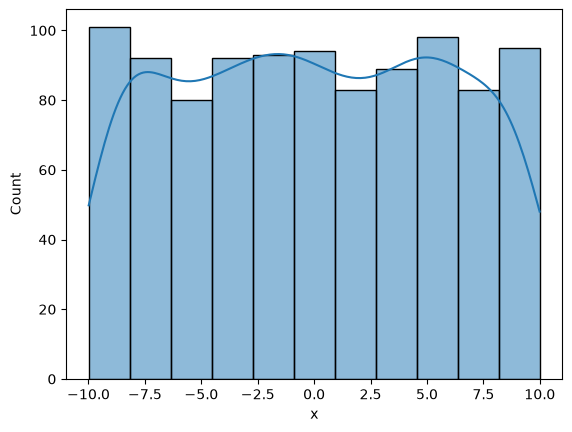

In [3]:
sns.histplot(data=data['x'], kde=True)

<Axes: xlabel='y', ylabel='Count'>

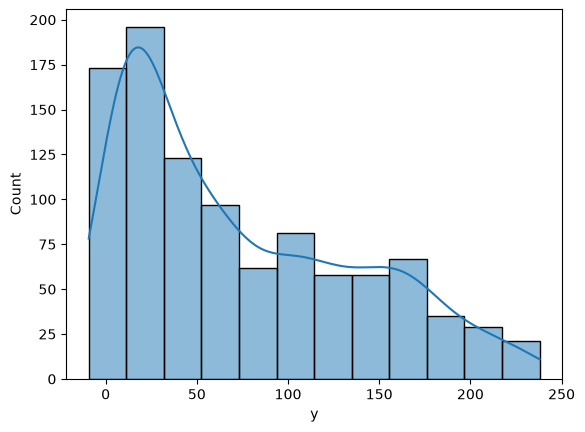

In [4]:
sns.histplot(data=data['y'], kde=True)

In [5]:
data['y_scaled'] = prep.scale(data['y'])

<Axes: xlabel='y_scaled', ylabel='Count'>

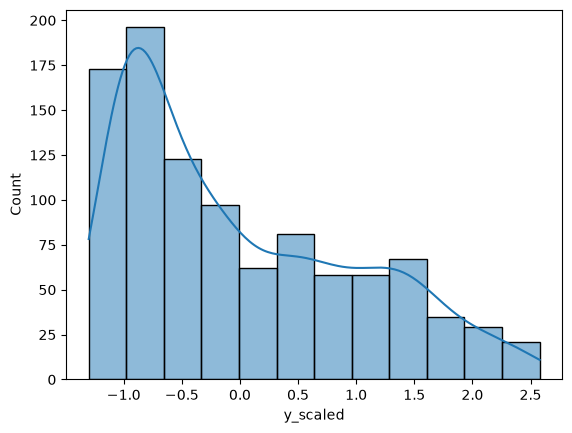

In [6]:
sns.histplot(data=data['y_scaled'], kde=True)

<Axes: xlabel='x', ylabel='y_scaled'>

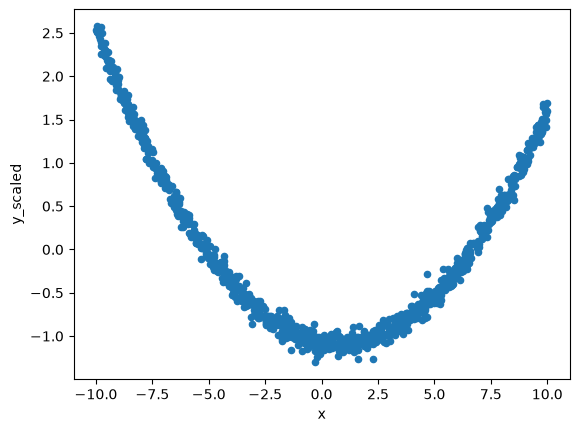

In [7]:
data.plot.scatter(x='x', y='y_scaled')

## Step 2: Extract Independent and Dependent Variables

In [8]:

# Extracting 'Level' as X and 'Salary' as y
X = data[['x']].values
y = data['y_scaled'].values
    

## Let's see what a simple linear model would look like

In [9]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.05]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.00132
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[184.92]


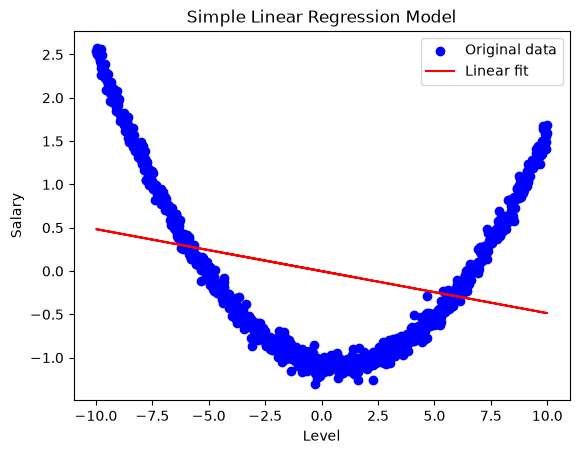

In [10]:
# Predict the salary values using the simple linear model 
y_pred = model.predict(X)

# Visualize the original data and the polynomial regression curve
plt.scatter(X, y, color='blue', label='Original data')
plt.plot(X, y_pred, color='red', label='Linear fit')
plt.title('Simple Linear Regression Model')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.legend()
plt.show()
    

## Now let's see if we can fix this with transforming our predictor features into polynomial features

## Step 3: Transform the Data into Polynomial Features

In [16]:

# Transform the data into polynomial features (degree=4)
poly = PolynomialFeatures(degree=4)
X_poly = poly.fit_transform(X)
    

In [17]:
X_poly

array([[ 1.00000000e+00,  1.40944532e+00,  1.98653612e+00,
         2.79991404e+00,  3.94632575e+00],
       [ 1.00000000e+00, -9.33737651e+00,  8.71866002e+01,
        -8.14094113e+02,  7.60150325e+03],
       [ 1.00000000e+00, -6.95129091e+00,  4.83204453e+01,
        -3.35889472e+02,  2.33486543e+03],
       ...,
       [ 1.00000000e+00, -4.59472445e+00,  2.11114927e+01,
        -9.70014917e+01,  4.45695125e+02],
       [ 1.00000000e+00,  1.49865067e+00,  2.24595382e+00,
         3.36590018e+00,  5.04430855e+00],
       [ 1.00000000e+00, -4.25757643e+00,  1.81269570e+01,
        -7.71769049e+01,  3.28586571e+02]], shape=(1000, 5))

## Step 4: Fit a Polynomial Regression Model

In [18]:

# Fit the linear regression model to the polynomial-transformed data
model = LinearRegression()
model.fit(X_poly, y)
    

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0. ,-0.05, 0.03,-0. , 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.071
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[87078.33,12344.94, 268.24, 72.67, 0. ]"


## Step 5: Predict and Visualize the Results

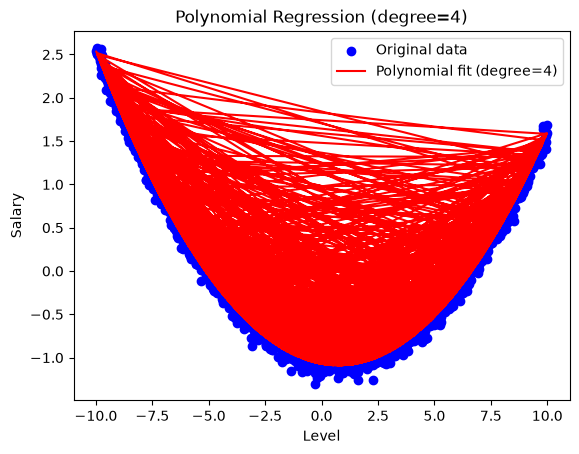

In [19]:

# Predict the salary values using the model
y_pred = model.predict(X_poly)

# Visualize the original data and the polynomial regression curve
plt.scatter(X, y, color='blue', label='Original data')
plt.plot(X, y_pred, color='red', label='Polynomial fit (degree=4)')
plt.title('Polynomial Regression (degree=4)')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.legend()
plt.show()
    

## Step 6: Evaluate the Model

In [20]:

from sklearn.metrics import r2_score

# Calculate the R-squared value to evaluate model performance
r2 = r2_score(y, y_pred)
r2
    

0.9943674959534129

In [21]:
def build_poly_regression_model(X, y, degree):
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    model = LinearRegression()
    model.fit(X_poly, y)
    y_pred = model.predict(X_poly)

    # Visualize the original data and the polynomial regression curve
    plt.scatter(X, y, color='blue', label='Original data')
    plt.plot(X, y_pred, color='red', label='Polynomial fit (degree=' + str(degree) + ')')
    plt.title('Polynomial Regression (degree=' + str(degree) + ')')
    plt.xlabel('Level')
    plt.ylabel('Salary')
    plt.legend()
    plt.show()
    r2 = r2_score(y, y_pred)
    print("R-squared for degree ", degree, ": ", r2)

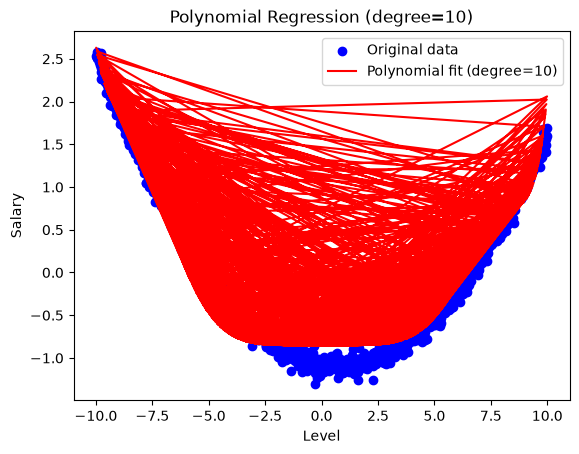

R-squared for degree  10 :  0.9601446059847335


In [22]:
build_poly_regression_model(X, y, 10)

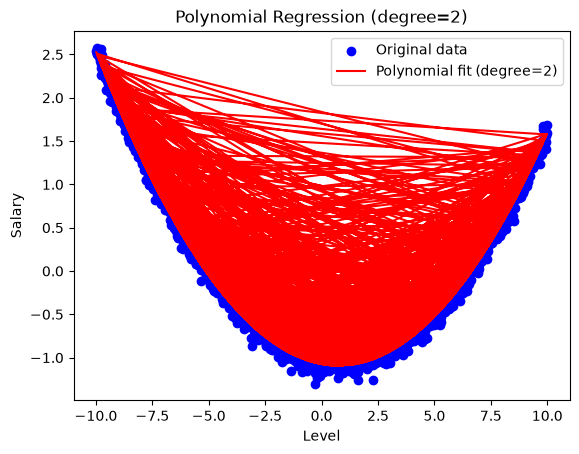

R-squared for degree  2 :  0.9943611667303734


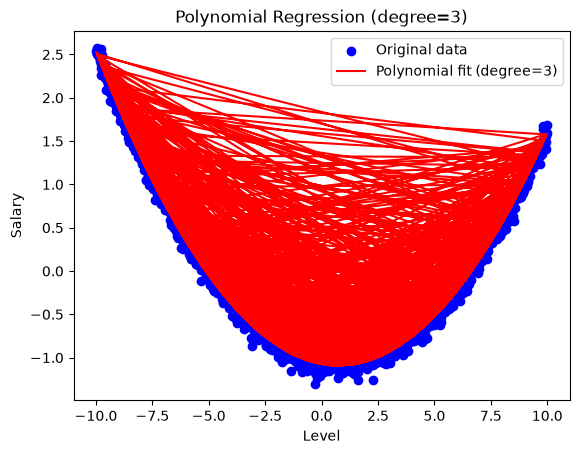

R-squared for degree  3 :  0.9943611745845353


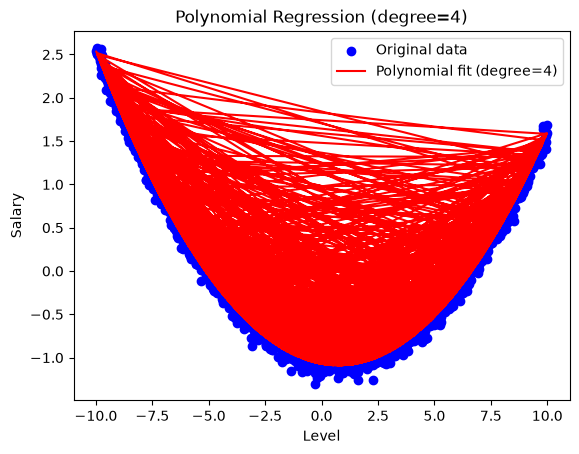

R-squared for degree  4 :  0.9943674959534129


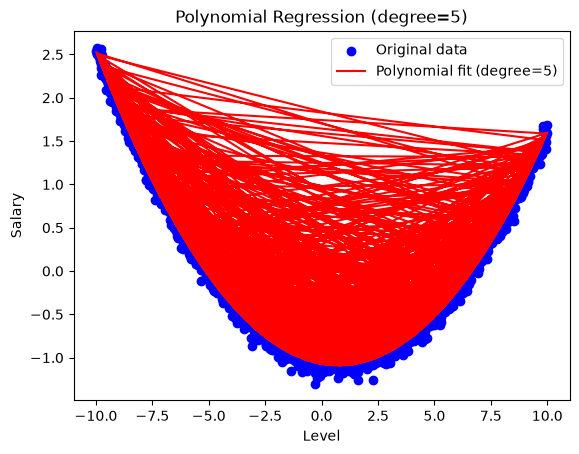

R-squared for degree  5 :  0.9943687470193008


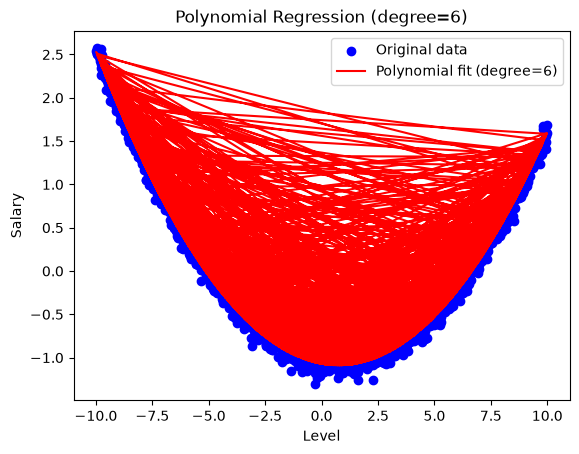

R-squared for degree  6 :  0.9943695274916905


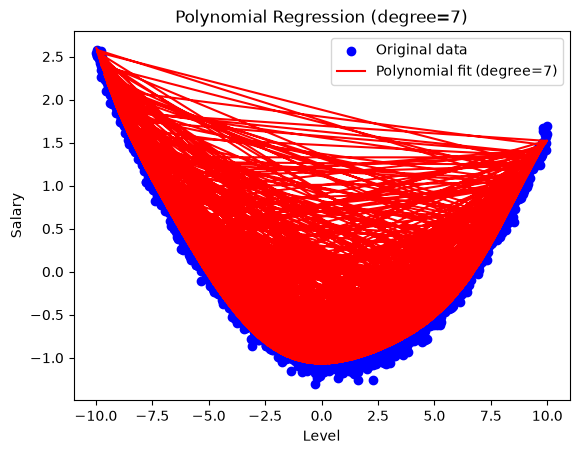

R-squared for degree  7 :  0.9929407261561757


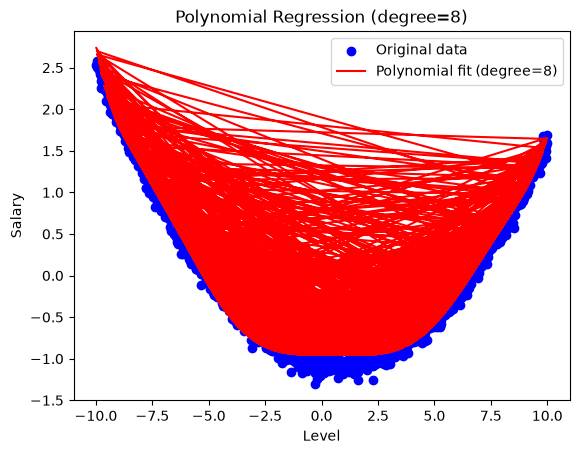

R-squared for degree  8 :  0.9892432501554543


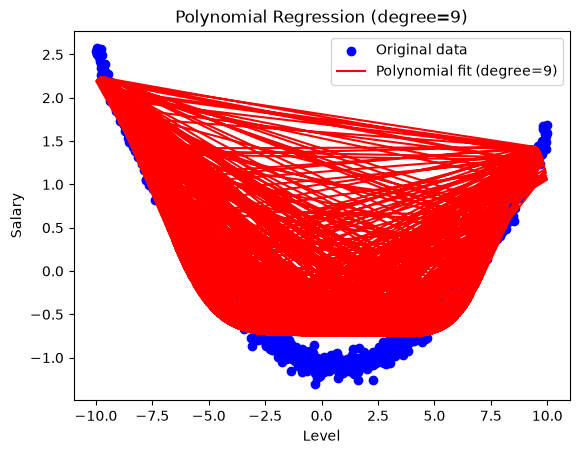

R-squared for degree  9 :  0.939737126415746


In [23]:
for i in range(2, 10):
    build_poly_regression_model(X, y, i)